In [1]:
import torch
from torchvision.transforms.functional import to_tensor
from PIL import Image

import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["image.cmap"] = "gray"

device = "cpu"

In [2]:
# "spiral" "monalisa" "retina"
test = "spiral"

In [3]:
Or = 16

match test:
    case "spiral":
        ground_truth = to_tensor(Image.open("spiral.tif").convert("L"))[0].to(dtype=torch.float, device=device) * 1.
        noisy = to_tensor(Image.open("noisyspiral.tif").convert("I"))[0].to(dtype=torch.float, device=device) / 255.**2
        scales = 4
        cut_freq = 0.5
        q = 0.33

    case "monalisa":
        ground_truth = to_tensor(Image.open("monalisa.tif").convert("L"))[0].to(dtype=torch.float, device=device) * 1.
        noisy = to_tensor(Image.open("noisymonalisa.tif").convert("I"))[0].to(dtype=torch.float, device=device) / 255.**2
        scales = 4
        cut_freq = 0.25
        q = 0.59


    # In this case the noise in the image is very high
    case "retina":
        ground_truth = to_tensor(Image.open("test.tif").convert("L"))[0].to(dtype=torch.float, device=device) * 1.
        noise = 0.2 * 1. * torch.randn(ground_truth.shape, device=device)#, (2., 2.)
        noisy = torch.clip(ground_truth + noise, 0., 1.)

        scales = 4
        cut_freq = 0.25

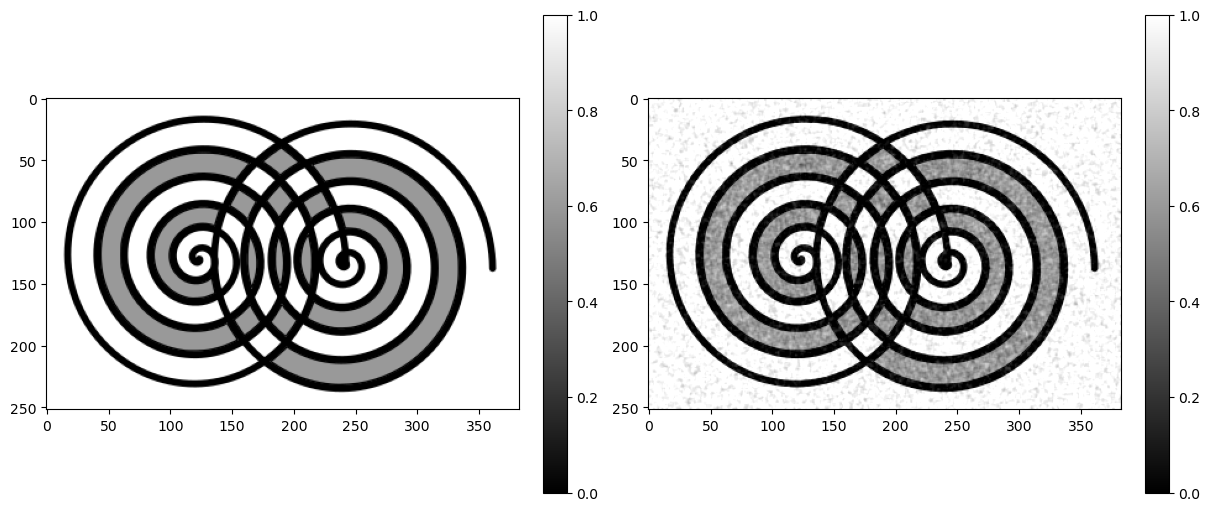

In [4]:

fig, ax = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
cbar = ax[0].imshow(ground_truth.cpu(), vmin=0., vmax=1.)
fig.colorbar(cbar, ax=ax[0])
cbar = ax[1].imshow(noisy.cpu(), vmin=0., vmax=1.)
fig.colorbar(cbar, ax=ax[1]);

In [5]:
from stPyr import SteerablePyramid
import torch.nn.functional as F

stp = SteerablePyramid(noScales=scales, noOrientations=Or,  cut_freq=cut_freq, decimate=False, a=2.0)

def thresh(x, t):
    return(F.relu(x-t)-F.relu(-x-t))



def statisticalEst(noisy, q = 0.59 ):
    Wx, WxLow = stp(noisy[None, None].clone())
    Wx_est = []
    for w in Wx:
        t = torch.quantile(
            w.abs().flatten(start_dim=-2),
            q=q,
            dim=-1,
            keepdim=True
        ).unsqueeze(-1)
        Wx_est.append(thresh(w,t))
    rec = stp.transpose(Wx_est, WxLow)
    

    return(rec)

In [6]:
rec = statisticalEst(noisy.clone(), q)[0,0]

PSNR
tensor(27.2653)


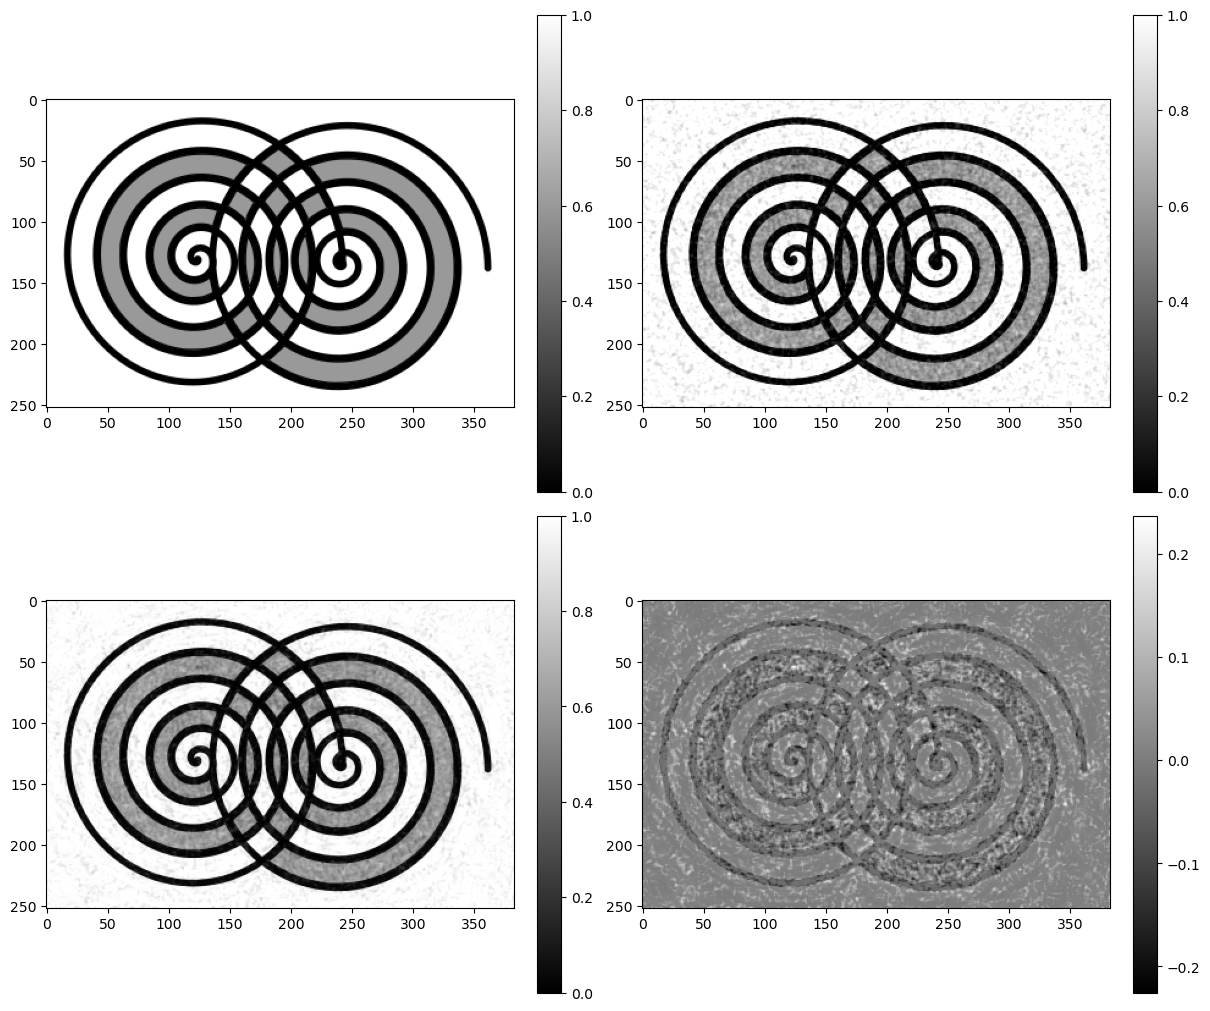

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10), layout="constrained")
cbar = ax[0, 0].imshow(ground_truth.cpu(), vmin=0., vmax=1.)
fig.colorbar(cbar, ax=ax[0, 0])
cbar = ax[0, 1].imshow(noisy.cpu(), vmin=0., vmax=1.)
fig.colorbar(cbar, ax=ax[0, 1])
cbar = ax[1, 0].imshow(torch.clip(rec, 0., 1.).cpu(), vmin=0., vmax=1.)
fig.colorbar(cbar, ax=ax[1, 0])
cbar = ax[1, 1].imshow((ground_truth - torch.clip(rec, 0., 1.)).cpu())
fig.colorbar(cbar, ax=ax[1, 1]);

psnr = -10*torch.log10( ((ground_truth - torch.clip(rec, 0., 1.)).cpu()**2).mean() )
print("PSNR")
print(psnr)

In [10]:
import numpy as np


def make_callback(args):
    def callback(xk):
        f = loss(xk, *args)
        print(f"loss={f:.6f}")
        print(f"x={xk}")
    return callback


def callback(xk, *args):
    func = loss(xk, *args)
    print(f"x = {xk}, loss = {func}")


def transform(z, a=0, b=1):
    x = a + (b-a)/(1 + np.exp(-z))
    return(x)

def inverse_transform(x, a=0, b=1):
    return np.log((x - a) / (b - x))

def loss(x, *args):
    """ loss
        Description:

            This function is employed for finetuning of the PnP model
        Inputs:
            * x: Parameters to be optimized, in the case of PnP is a mixture
                component \gamma and the threshold level sigma
            * args: Additional optimizaton arguments
                * cnn

    """
    noisy, ground_truth = args


    # For some reason it works better to make the search space in 
    # log scale. After the optimization is finished make 2**optimizer.x
    #k = 2**x[0] # Using the scale
    print(x)
    k = transform(x[0])

    rec = statisticalEst(noisy, k)
        
    mse =  ((ground_truth - rec)**2).mean().item()
    return( mse )





In [11]:
# Let's optimize the value of sig for the deblurring task

from scipy.optimize import minimize


ep = 0.25
λ = 50

#x0 = np.ones( 1 )
x0 = np.array([inverse_transform(0.7)])
print(x0)


options = {"disp":True,  "maxiter":20, "maxfev": 40, "fatol":1.0e-4, "xatol": 0.005}
args = (noisy, ground_truth) 
optimizer = minimize(loss, x0=x0, args=args,
                        method='Nelder-Mead',  options=options, callback=make_callback(args))

[0.84729786]
[0.84729786]
[0.88966275]
[0.80493297]
[0.76256807]
[0.76256807]
loss=0.005029
x=[0.76256807]
[0.67783829]
[0.5931085]
[0.5931085]
loss=0.003872
x=[0.5931085]
[0.42364893]
[0.25418936]
[0.25418936]
loss=0.002546
x=[0.25418936]
[-0.08472979]
[-0.42364893]
[-0.42364893]
loss=0.001906
x=[-0.42364893]
[-1.10148722]
[-0.76256807]
[-0.76256807]
loss=0.001880
x=[-0.76256807]
[-1.10148722]
[-0.5931085]
[-0.76256807]
loss=0.001880
x=[-0.76256807]
[-0.93202765]
[-0.67783829]
[-0.67783829]
loss=0.001879
x=[-0.67783829]
[-0.5931085]
[-0.72020318]
[-0.67783829]
loss=0.001879
x=[-0.67783829]
[-0.6354734]
[-0.69902073]
[-0.69902073]
loss=0.001879
x=[-0.69902073]
[-0.72020318]
[-0.68842951]
[-0.69902073]
loss=0.001879
x=[-0.69902073]
[-0.70961196]
[-0.69372512]
[-0.69902073]
loss=0.001879
x=[-0.69902073]
[-0.70431635]
[-0.70166854]
[-0.69902073]
loss=0.001879
x=[-0.69902073]
[-0.69902073]
loss=0.001879
x=[-0.69902073]
Optimization terminated successfully.
         Current function value: 

In [12]:
optimizer

       message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 0.0018791250186040998
             x: [-6.990e-01]
           nit: 13
          nfev: 26
 final_simplex: (array([[-6.990e-01],
                       [-7.017e-01]]), array([ 1.879e-03,  1.879e-03]))

In [13]:
transform(optimizer.x)

array([0.33202938])